# Core Loss Without the *P. viridiflava* / *Sphingomonas* Signal (Recalled Species)

Core loss (core species > 80% seasonal prevalence making up a low % of reads; `core_loss_group_size_sweep_de.ipynb`) is mainly loss of two species: *Sphingomonas* sp000786205 (37% of the abundance lost at n = 115) and *Pseudomonas viridiflava* (19%). Losing *P. viridiflava* on its own gives photosynthesis up and defense down (`core_species_depletion_de.ipynb`), the same direction as core loss. This notebook asks what core loss looks like once those two species are taken out, in two ways:

1. **Redefined core loss.** Both species are dropped from the core set. Each plant's core abundance is then the % of its reads in the other 38 core species, **out of the reads not in those two species**, so a *P. viridiflava* bloom or *Sphingomonas* drop can't change the others' share just by changing the denominator. Plants are ranked on this (lowest `n`, absolute as in the sweep) and also within timepoint (lowest 15%).
2. **Adjusted DE.** The original core-loss groups are kept, and the log abundances of both species (within-timepoint z-scores) go into the DESeq2 design as covariates: `~timepoint + P. viridiflava + Sphingomonas + group`. The group effect is what remains after their effect is accounted for. The defense-score difference is adjusted the same way.

Each is compared with the original core loss at the same group sizes: DE genes, log2FC correlation, GO enrichment and defense score. Fits are cached in `Generated_data/core_loss_without_pv_sph_recalled_species/`; the original core-loss fits come from the sweep's cache.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import contextlib
import io
from pathlib import Path
import statsmodels.formula.api as smf
from scipy.stats import zscore
import pydeseq2.default_inference
import pydeseq2.ds
import pydeseq2.dds

from scipy.stats import spearmanr
import Go_tools

###Define Thresholds
removed_species = ["s__Pseudomonas_E_647464 viridiflava", "s__Sphingomonas_L_486704 sp000786205"]
core_prevalence_threshold = 0.8
group_sizes = [60, 80, 100, 115, 120]
within_timepoint_fraction = 0.15
log_pseudocount = 0.05
expressed_gene_reads_threshold = 2000
number_of_samples_expressed_in_threshold = 21
n_cpus = 10
generated = Path("/Users/michael/Data/Luke_terrace_experiment/General_data/Generated_data")
results_dir = generated / "core_loss_without_pv_sph_recalled_species"
sweep_dir = generated / "dysbiosis_threshold_sweep_recalled_species"

In [2]:
transcriptome = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/plate1_5_tpm_normalized.csv",
    index_col=0,
)
rows_to_drop_expression_data = [
    "A2450525897_n01_undetermined",
    "A2449446903_n01_undetermined",
    "B250508004_n01_undetermined",
    "B2449500127_n01_undetermined",
]
transcriptome = transcriptome.drop(index=rows_to_drop_expression_data)
transcriptome = transcriptome.sort_index()
metadata = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/Plates_1_to_5_metadata_merged_luke.csv",
    index_col=0,
)
raw_transcriptome = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/plate1_5_for_norm.csv",
    index_col=0,
)

## Get plate 5 samples and remove what they replaced from the metadata to avoid duplicates
plate_5_replacements = metadata.loc[metadata["rnaprepplate"] == "LICRNA_05"]
non_plate_5_samples = metadata.loc[metadata["rnaprepplate"] != "LICRNA_05"]
replaced_samples = non_plate_5_samples.loc[
    non_plate_5_samples["sampID"].isin(plate_5_replacements["sampID"])
]
trimmed_metadata = metadata.drop(index=replaced_samples.index)
### For remaining duplicated sampIDs, drop the transcriptome with fewer total reads
double_duplicates = (
    trimmed_metadata.loc[trimmed_metadata.duplicated(subset="sampID", keep=False)]
    .sort_values(by="Total Reads")
    .drop_duplicates(subset="sampID", keep="first")
)
trimmed_metadata = trimmed_metadata.drop(index=double_duplicates.index)
### Drop failed libraries with too few reads (e.g. LIC162 has 66 total reads)
min_total_reads = 250_000
low_read_samples = trimmed_metadata.index[trimmed_metadata["Total Reads"] < min_total_reads]
trimmed_metadata = trimmed_metadata.drop(index=low_read_samples)
print(f"Dropped {len(low_read_samples)} transcriptomes with < {min_total_reads:,} total reads")
trimmed_transcriptome = transcriptome.loc[trimmed_metadata.index]
trimmed_raw_transcriptome = raw_transcriptome.loc[trimmed_metadata.index]
print("Transcriptomes after removing replicates:", len(trimmed_metadata))

# Same gene filters as the dysbiosis DE notebook
cleaned_raw_transcriptome = trimmed_raw_transcriptome.loc[
    :, trimmed_raw_transcriptome.sum() > expressed_gene_reads_threshold
]
cleaned_raw_transcriptome = cleaned_raw_transcriptome.loc[
    :, (cleaned_raw_transcriptome > 1).sum() > number_of_samples_expressed_in_threshold
]
print("Genes kept for DESeq2:", cleaned_raw_transcriptome.shape[1])

# Defense score: only used to describe the groups, never to define them
defense_gene_list = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/Generated_data/load_correlated_genes_union_GO_and_FLG_plates_1_to_5.csv"
)
defense_genes = set(defense_gene_list["gene"])
transcriptome_in_defense_gene_list = trimmed_transcriptome.loc[
    :, trimmed_transcriptome.columns.isin(defense_genes)
]
trimmed_metadata["Defense Score"] = transcriptome_in_defense_gene_list.apply(zscore).sum(
    axis=1
) / len(defense_gene_list)

# Old species-level DE genes (59, plates 1-5), for overlap
old_de_genes = set(
    pd.read_csv(
        "/Users/michael/Data/Luke_terrace_experiment/General_data/Junk_data/large_deseq_gene_list_all_plates.csv",
        header=None,
    )[0]
)

Dropped 6 transcriptomes with < 250,000 total reads
Transcriptomes after removing replicates: 426
Genes kept for DESeq2: 18032


## Species abundance

In [3]:
### Recalled species table. Species under 0.05% of a sample (AbundR == 0) are
### dropped, as in the recalled-genera table
min_abundR = 1
### Plant samples missing from the recalled-genera table (LIC148, LIC162, LIC584 have
### < 1,600 16S reads; LIC577 unknown). Kept for now: see to_revisit.txt
samples_to_drop = []  # ["LIC148", "LIC162", "LIC577", "LIC584"]
microbiome_abundance = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/Oct_2026_recalled_species/lic16s_species_relabund.csv"
)
microbiome_abundance = microbiome_abundance.loc[
    (microbiome_abundance["AbundR"] >= min_abundR)
    & ~microbiome_abundance["Sample"].isin(samples_to_drop)
].copy()
# No seascirc column in the species table: circadian timepoints start with "c"
microbiome_abundance["seascirc"] = np.where(
    microbiome_abundance["timepoint"].str.startswith("c"), "circadian", "seasonal"
)
plant_microbiome = microbiome_abundance.loc[microbiome_abundance["sample.type"] == "plant"]

# Sample x species abundance as % of each sample's reads (absent species = 0)
species_abundance_matrix = pd.pivot_table(
    plant_microbiome, values="Abundance", index="Sample", columns="Species", aggfunc="sum", fill_value=0
)
species_abundance_matrix = species_abundance_matrix.div(species_abundance_matrix.sum(axis=1), axis=0) * 100
seasonal_samples = plant_microbiome.loc[plant_microbiome["seascirc"] == "seasonal", "Sample"].unique()
seasonal_prevalence = (species_abundance_matrix.loc[seasonal_samples] > 0).mean()

# Transcriptome samples, all with a microbiome profile
de_samples = trimmed_metadata.index[trimmed_metadata["sampID"].isin(species_abundance_matrix.index)]
print("Transcriptomes with a microbiome profile:", len(de_samples), "of", len(trimmed_metadata))
sample_species = species_abundance_matrix.loc[trimmed_metadata.loc[de_samples, "sampID"]].set_index(de_samples)

Transcriptomes with a microbiome profile: 426 of 426


In [4]:
inference = pydeseq2.default_inference.DefaultInference(n_cpus=n_cpus)
de_counts = cleaned_raw_transcriptome.loc[de_samples]
results_dir.mkdir(parents=True, exist_ok=True)


def run_deseq(run_id, high_samples):
    """DESeq2 ~timepoint + group (High vs Low) on all DE samples. Results are cached
    in results_dir, so a re-run only fits groupings it hasn't seen."""
    cache = results_dir / f"{run_id}.csv"
    if cache.exists():
        return pd.read_csv(cache, index_col=0)
    design_metadata = pd.DataFrame(
        {
            "timepoint": trimmed_metadata.loc[de_samples, "timepoint"],
            "group": np.where(de_samples.isin(high_samples), "High", "Low"),
        },
        index=de_samples,
    )
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        dds = pydeseq2.dds.DeseqDataSet(
            counts=de_counts,
            metadata=design_metadata,
            design="~timepoint+group",
            refit_cooks=True,
            inference=inference,
            quiet=True,
        )
        dds.deseq2()
        stats = pydeseq2.ds.DeseqStats(
            dds, contrast=["group", "High", "Low"], inference=inference, quiet=True
        )
        stats.summary()
    results = stats.results_df
    results.to_csv(cache)
    return results


def summarise_run(results, high_samples):
    """DE gene counts, plus how the group's defense score compares (timepoint-adjusted)."""
    significant = results.loc[results["padj"] < 0.05]
    defense_df = trimmed_metadata.loc[de_samples, ["timepoint", "Defense Score"]].assign(
        high=de_samples.isin(high_samples).astype(int)
    )
    fit = smf.ols("Q('Defense Score') ~ C(timepoint) + high", data=defense_df).fit()
    return {
        "n High": int(defense_df["high"].sum()),
        "significant (padj < 0.05)": len(significant),
        "up": int((significant["log2FoldChange"] > 0).sum()),
        "down": int((significant["log2FoldChange"] < 0).sum()),
        "significant, |LFC| > 1": int((significant["log2FoldChange"].abs() > 1).sum()),
        "min padj": results["padj"].min(),
        "defense genes among significant": len(set(significant.index) & defense_genes),
        "old DE genes among significant": len(set(significant.index) & old_de_genes),
        "defense score diff (timepoint-adjusted)": fit.params["high"],
        "defense score diff p": fit.pvalues["high"],
    }

In [5]:
timepoint = trimmed_metadata.loc[de_samples, "timepoint"]
core_species = seasonal_prevalence.index[seasonal_prevalence > core_prevalence_threshold]
remaining_core = core_species.drop(removed_species)
core_abund = sample_species[core_species].sum(axis=1)
remaining_core_abund = sample_species[remaining_core].sum(axis=1) / (100 - sample_species[removed_species].sum(axis=1)) * 100


def within_timepoint_z(score):
    grouped = score.groupby(timepoint)
    return ((score - grouped.transform("mean")) / grouped.transform("std")).fillna(0)


covariates = pd.DataFrame(
    {
        "pviridiflava": within_timepoint_z(np.log10(sample_species[removed_species[0]] + log_pseudocount)),
        "sphingomonas": within_timepoint_z(np.log10(sample_species[removed_species[1]] + log_pseudocount)),
    }
)
print(f"Core species: {len(core_species)}; without the two removed: {len(remaining_core)}")
print(f"Spearman, original vs redefined core abundance: {spearmanr(core_abund, remaining_core_abund)[0]:.2f}")
print(f"Median share of reads in the two removed species: {sample_species[removed_species].sum(axis=1).median():.1f}%")

Core species: 40; without the two removed: 38
Spearman, original vs redefined core abundance: 0.92
Median share of reads in the two removed species: 17.4%


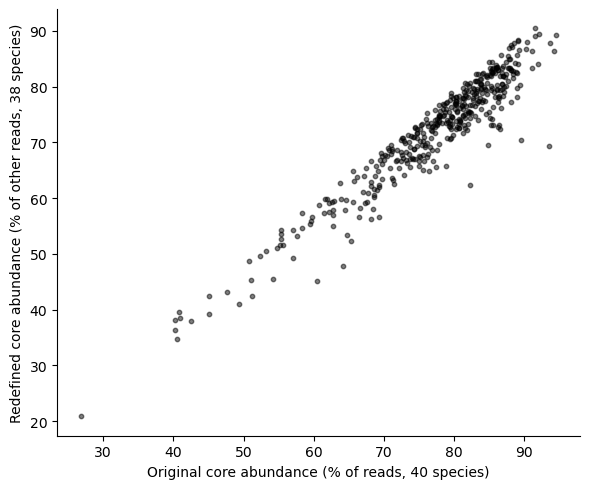

In [6]:
fig, ax = plt.subplots(figsize=(6, 5))
fig.patch.set_facecolor("white")
ax.scatter(core_abund, remaining_core_abund, s=10, alpha=0.5, color="black")
ax.set_xlabel("Original core abundance (% of reads, 40 species)")
ax.set_ylabel("Redefined core abundance (% of other reads, 38 species)")
sns.despine()
plt.tight_layout()

## DESeq2 runs

`run_adjusted_deseq` is `run_deseq` with the two species' abundances added to the design.

In [7]:
def run_adjusted_deseq(run_id, high_samples):
    cache = results_dir / f"{run_id}.csv"
    if cache.exists():
        return pd.read_csv(cache, index_col=0)
    design_metadata = covariates.assign(
        timepoint=trimmed_metadata.loc[de_samples, "timepoint"],
        group=np.where(de_samples.isin(high_samples), "High", "Low"),
    )
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        dds = pydeseq2.dds.DeseqDataSet(
            counts=de_counts, metadata=design_metadata, design="~timepoint+pviridiflava+sphingomonas+group",
            refit_cooks=True, inference=inference, quiet=True,
        )
        dds.deseq2()
        stats = pydeseq2.ds.DeseqStats(dds, contrast=["group", "High", "Low"], inference=inference, quiet=True)
        stats.summary()
    results = stats.results_df
    results.to_csv(cache)
    return results


def adjusted_defense_difference(high_samples):
    df = covariates.assign(
        timepoint=timepoint, defense=trimmed_metadata.loc[de_samples, "Defense Score"], high=de_samples.isin(high_samples).astype(float)
    )
    fit = smf.ols("defense ~ C(timepoint) + pviridiflava + sphingomonas + high", data=df).fit()
    return fit.params["high"], fit.pvalues["high"]


def fit_from(cache_dir, run_id, high_samples):
    global results_dir
    own_dir = results_dir
    results_dir = Path(cache_dir)
    try:
        return run_deseq(run_id, high_samples)
    finally:
        results_dir = own_dir


def defense_gene_counts(results):
    defense_results = results.loc[results.index.isin(defense_genes)]
    significant = defense_results["padj"] < 0.05
    return {
        "defense genes up": int((significant & (defense_results["log2FoldChange"] > 0)).sum()),
        "defense genes down": int((significant & (defense_results["log2FoldChange"] < 0)).sum()),
    }


runs = {}
rows = []
for n in group_sizes:
    original_group = core_abund.sort_values().index[:n]
    redefined_group = remaining_core_abund.sort_values().index[:n]
    for version, results, group in [
        ("original core loss", fit_from(sweep_dir, f"core_loss_prev0.8_n{n}", original_group), original_group),
        ("redefined (without P. viridiflava, Sphingomonas)", run_deseq(f"core_loss_without_pv_sph_n{n}", redefined_group), redefined_group),
        ("original groups, adjusted for both species", run_adjusted_deseq(f"core_loss_adjusted_pv_sph_n{n}", original_group), original_group),
    ]:
        runs[(version, n)] = (results, group)
        summary = summarise_run(results, group)
        if version.startswith("original groups, adjusted"):
            summary["defense score diff (timepoint-adjusted)"], summary["defense score diff p"] = adjusted_defense_difference(group)
        rows.append({"version": version, "group size": n, "plants shared with original group": int(pd.Index(group).isin(original_group).sum()), **summary, **defense_gene_counts(results)})

within_group = remaining_core_abund.pipe(lambda s: (-within_timepoint_z(s)).sort_values(ascending=False).index[: round(within_timepoint_fraction * len(de_samples))])
within_results = run_deseq("core_loss_without_pv_sph_within_timepoint", within_group)
runs[("redefined, within timepoint", len(within_group))] = (within_results, within_group)
rows.append({"version": "redefined, within timepoint", "group size": len(within_group), "plants shared with original group": np.nan, **summarise_run(within_results, within_group), **defense_gene_counts(within_results)})

comparison = pd.DataFrame(rows)
reference = runs[("original core loss", 115)][0]
reference_significant = set(reference.index[reference["padj"] < 0.05])
comparison["LFC rho with original n=115"] = [
    spearmanr(runs[(v, n)][0]["log2FoldChange"], reference["log2FoldChange"].reindex(runs[(v, n)][0].index), nan_policy="omit")[0]
    for v, n in zip(comparison["version"], comparison["group size"])
]
comparison["shared DE genes with original n=115"] = [
    len(set(runs[(v, n)][0].index[runs[(v, n)][0]["padj"] < 0.05]) & reference_significant) for v, n in zip(comparison["version"], comparison["group size"])
]
comparison.to_csv(results_dir / "core_loss_without_pv_sph_summary.csv", index=False)
comparison.pivot_table(index="group size", columns="version", values="significant (padj < 0.05)")

version,original core loss,"original groups, adjusted for both species","redefined (without P. viridiflava, Sphingomonas)","redefined, within timepoint"
group size,,,,
60,161.0,157.0,234.0,NaN
64,NaN,NaN,NaN,1.0
80,91.0,28.0,2.0,NaN
100,635.0,168.0,179.0,NaN
115,1211.0,453.0,191.0,NaN
120,948.0,254.0,199.0,NaN


In [8]:
comparison.drop(columns=["old DE genes among significant"]).round(3)

,version,group size,plants shared with original group,n High,significant (padj < 0.05),up,down,"significant, |LFC| > 1",min padj,defense genes among significant,defense score diff (timepoint-adjusted),defense score diff p,defense genes up,defense genes down,LFC rho with original n=115,shared DE genes with original n=115
0,original core loss,60,60.0,60,161,69,92,1,0.005,2,0.006,0.930,1,1,0.632,110
1,"redefined (without P. viridiflava, Sphingomonas)",60,53.0,60,234,127,107,0,0.001,3,0.035,0.649,2,1,0.636,151
2,"original groups, adjusted for both species",60,60.0,60,157,68,89,2,0.002,1,0.039,0.590,1,0,0.510,72
3,original core loss,80,80.0,80,91,42,49,0,0.002,2,-0.005,0.936,0,2,0.784,75
4,"redefined (without P. viridiflava, Sphingomonas)",80,73.0,80,2,1,1,0,0.037,0,-0.040,0.552,0,0,0.724,2
5,"original groups, adjusted for both species",80,80.0,80,28,13,15,0,0.006,1,0.033,0.622,0,1,0.663,22
6,original core loss,100,100.0,100,635,279,356,1,0.001,13,-0.069,0.245,4,9,0.934,581
7,"redefined (without P. viridiflava, Sphingomonas)",100,86.0,100,179,130,49,0,0.002,4,-0.055,0.372,3,1,0.811,161
8,"original groups, adjusted for both species",100,100.0,100,168,88,80,0,0.008,3,-0.041,0.503,1,2,0.865,159
9,original core loss,115,115.0,115,1211,481,730,3,0.000,22,-0.085,0.131,9,13,1.000,1211


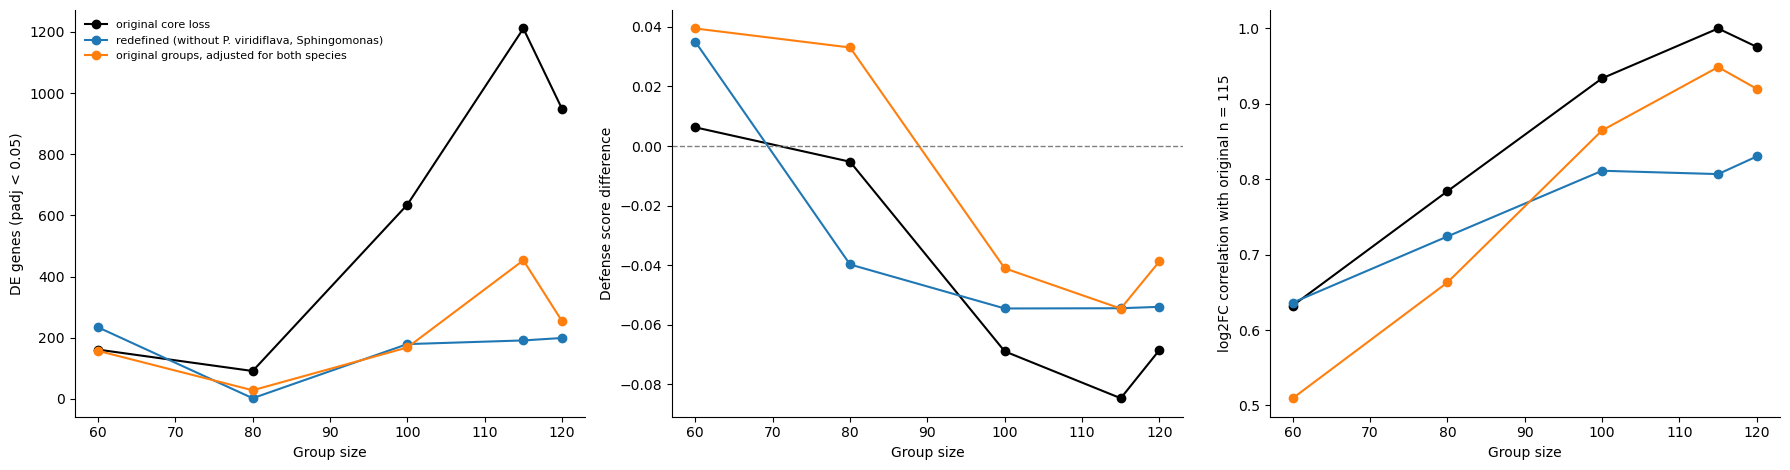

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
fig.patch.set_facecolor("white")
colors = {"original core loss": "black", "redefined (without P. viridiflava, Sphingomonas)": "tab:blue", "original groups, adjusted for both species": "tab:orange"}
for version, color in colors.items():
    part = comparison.loc[comparison["version"] == version]
    axes[0].plot(part["group size"], part["significant (padj < 0.05)"], marker="o", color=color, label=version)
    axes[1].plot(part["group size"], part["defense score diff (timepoint-adjusted)"], marker="o", color=color)
    axes[2].plot(part["group size"], part["LFC rho with original n=115"], marker="o", color=color)
axes[0].set_ylabel("DE genes (padj < 0.05)")
axes[1].set_ylabel("Defense score difference")
axes[1].axhline(0, color="gray", linestyle="dashed", linewidth=1)
axes[2].set_ylabel("log2FC correlation with original n = 115")
axes[0].legend(frameon=False, fontsize=8)
for ax in axes:
    ax.set_xlabel("Group size")
    sns.despine(ax=ax)
plt.tight_layout()

## GO enrichment

For the run with the most DE genes in each version, and the within-timepoint version.

In [10]:
go_term_matrix = pd.read_csv("/Users/michael/Data/Reference_data/Arabdidopsis_go_matrix_from_tair_gaf.csv", index_col=0)
go_term_names = pd.read_csv("/Users/michael/Data/Reference_data/goterm_names.csv", index_col=0)
background_genes = de_counts.columns.tolist()


def go_enrichment(genes):
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        tables = Go_tools.generate_contigency_tables(go_annotations=go_term_matrix, gene_list=list(genes), use_background_genes=True, background_genes=background_genes)
        results = Go_tools.multi_hypothesis_correct_fishers_exact(
            Go_tools.fishers_exact_on_contigency_tables(all_go_contigency_tables=tables, original_GO_term_panda=go_term_matrix)
        )
    return results.merge(go_term_names, left_index=True, right_index=True, how="left").sort_values("P_value")


best_runs = comparison.loc[comparison.groupby("version")["significant (padj < 0.05)"].idxmax(), ["version", "group size"]]
for _, row in best_runs.iterrows():
    results = runs[(row["version"], row["group size"])][0]
    significant = results.loc[results["padj"] < 0.05]
    for direction, genes in [("up", significant.index[significant["log2FoldChange"] > 0]), ("down", significant.index[significant["log2FoldChange"] < 0])]:
        print(f"\n=== {row['version']}, n = {row['group size']}: {direction} in core-loss plants ({len(genes)} genes) ===")
        if len(genes) >= 10:
            display(go_enrichment(genes).head(10)[["P_value", "x"]])


=== original core loss, n = 115: up in core-loss plants (481 genes) ===


,P_value,x
GO:0009570,4.379357e-91,chloroplast stroma
GO:0009941,1.433706e-77,chloroplast envelope
GO:0009579,3.293360e-67,thylakoid
GO:0009507,2.471633e-61,chloroplast
GO:0003729,6.472114e-55,mRNA binding
GO:0009534,1.276296e-46,chloroplast thylakoid
GO:0009535,2.209751e-44,chloroplast thylakoid membrane
GO:0006412,2.437289e-32,translation
GO:0005829,6.434840e-30,cytosol
GO:0022626,1.150061e-29,cytosolic ribosome



=== original core loss, n = 115: down in core-loss plants (730 genes) ===


,P_value,x
GO:0050832,7.137752e-07,defense response to fungus
GO:0005515,2.251921e-06,protein binding
GO:0003700,7.037414e-06,DNA-binding transcription factor activity
GO:0002237,1.219791e-05,response to molecule of bacterial origin
GO:0010150,3.663543e-05,leaf senescence
GO:0042742,3.663543e-05,defense response to bacterium
GO:0009617,9.623322e-05,response to bacterium
GO:0071456,1.200523e-04,cellular response to hypoxia
GO:0004842,1.792599e-04,ubiquitin-protein transferase activity
GO:0005776,2.319796e-04,autophagosome



=== original groups, adjusted for both species, n = 115: up in core-loss plants (217 genes) ===


,P_value,x
GO:0009570,1.961650e-36,chloroplast stroma
GO:0009941,7.336631e-30,chloroplast envelope
GO:0009579,4.884438e-28,thylakoid
GO:0009534,9.008802e-23,chloroplast thylakoid
GO:0009507,4.833850e-22,chloroplast
GO:0003729,4.833850e-22,mRNA binding
GO:0009535,3.838351e-21,chloroplast thylakoid membrane
GO:0006412,2.829343e-14,translation
GO:0022626,5.229571e-14,cytosolic ribosome
GO:0022625,2.411838e-11,cytosolic large ribosomal subunit


... (3 outputs left out)

,P_value,x
GO:0009941,1.280470e-19,chloroplast envelope
GO:0009534,5.115033e-19,chloroplast thylakoid
GO:0009579,1.015396e-16,thylakoid
GO:0009535,1.130304e-16,chloroplast thylakoid membrane
GO:0009570,1.504037e-15,chloroplast stroma
GO:0009507,2.271792e-14,chloroplast
GO:0003729,2.560747e-12,mRNA binding
GO:0005829,1.357467e-09,cytosol
GO:0048046,2.636223e-07,apoplast
GO:0009536,4.137360e-04,plastid



=== redefined (without P. viridiflava, Sphingomonas), n = 60: down in core-loss plants (107 genes) ===


,P_value,x
GO:0000001,1.0,mitochondrion inheritance
GO:0000009,1.0,"alpha-1,6-mannosyltransferase activity"
GO:0000012,1.0,single strand break repair
GO:0000014,1.0,single-stranded DNA endodeoxyribonuclease acti...
GO:0000023,1.0,maltose metabolic process
GO:0000024,1.0,maltose biosynthetic process
GO:0000025,1.0,maltose catabolic process
GO:0000026,1.0,"alpha-1,2-mannosyltransferase activity"
GO:0000027,1.0,ribosomal large subunit assembly
GO:0000028,1.0,ribosomal small subunit assembly



=== redefined, within timepoint, n = 64: up in core-loss plants (1 genes) ===

=== redefined, within timepoint, n = 64: down in core-loss plants (0 genes) ===


## What the redefined group looks like

Which remaining core species are lost, and what replaces them, in the redefined group at n = 115.

In [11]:
group = runs[("redefined (without P. viridiflava, Sphingomonas)", 115)][1]
in_group = de_samples.isin(group)
loss = (sample_species.loc[~in_group, remaining_core].mean() - sample_species.loc[in_group, remaining_core].mean()).sort_values(ascending=False)
gain = (sample_species.loc[in_group].mean() - sample_species.loc[~in_group].mean()).drop(core_species).sort_values(ascending=False)
print("Months in the group:", trimmed_metadata.loc[group, "Sample Month"].value_counts().to_dict())
print(f"P. viridiflava median %: group {sample_species.loc[in_group, removed_species[0]].median():.2f} vs rest {sample_species.loc[~in_group, removed_species[0]].median():.2f}")
print(f"Sphingomonas median %: group {sample_species.loc[in_group, removed_species[1]].median():.2f} vs rest {sample_species.loc[~in_group, removed_species[1]].median():.2f}")
display(pd.DataFrame({"core species lost (% points)": loss.head(10)}).round(3))
display(pd.DataFrame({"non-core species gained (% points)": gain.head(10)}).round(3))

Months in the group: {'November': 36, 'February': 27, 'December': 21, 'March': 18, 'January': 13}
P. viridiflava median %: group 0.65 vs rest 1.28
Sphingomonas median %: group 11.21 vs rest 14.87


,core species lost (% points)
Species,
s__Flavobacterium chilense,3.304
g__Limnohabitans_A Genus,2.558
s__Flavobacterium noncentrifugens,2.326
f__Burkholderiaceae_A_595421 Family,1.717
s__Variovorax paradoxus_C,1.008
g__Janthinobacterium_571130 Genus,1.001
s__Sphingomonas_L_486704 sp001421805,0.905
s__Rhodoferax_C aquaticus,0.803
s__Sphingomonas_L_486704 sp001423845,0.737


,non-core species gained (% points)
Species,
s__Sphingomonas_L_486704 metalli,1.553
s__Duganella zoogloeoides,1.340
s__Sphingomonas_L_486704 yunnanensis,1.038
s__Massilia violaceinigra,0.856
s__Pseudoduganella violaceinigra,0.852
s__Massilia aurea,0.512
s__Telluria sp001412595,0.448
s__Sphingomonas_L_486704 paucimobilis,0.443
s__Pseudomonas_E_647464 avellanae,0.408
